In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# récupération du dataset nettoyé
df_clean = pd.read_csv("csv/train_clean.csv")

df_clean.head()

,PassengerId,Survived,Pclass,Name,Male,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,S


In [28]:
# choix des colonnes à utiliser pour l'entrainement (celles présentant le plus de corrélation avec la colonne "Survived")

X = df_clean[['Pclass', 'Male', 'Age','Fare']]
y = df_clean["Survived"]

In [ ]:
# Division des données en ensemble d'entrainement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Création du scaler
scaler = StandardScaler()

# Calcul des paramètres sur les données train
X_train = scaler.fit_transform(X_train)

# Application des mêmes paramètres aux données de test
X_test = scaler.transform(X_test)

# Création du modèle KNN
model_KNN = KNeighborsClassifier(n_neighbors=6)

# Entrainement du modèle
model_KNN.fit(X_train, y_train)

# Test du modèle
y_test_pred = model_KNN.predict(X_test)

# Evaluation du modèle
print(f"test score: {model_KNN.score(X_test, y_test)}")
print(f"train score: {model_KNN.score(X_train, y_train)}")
print(f"classification_report:\n{classification_report(y_test, y_test_pred)}")


test score: 0.8314606741573034
train score: 0.8607594936708861
classification_report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86       109
           1       0.80      0.75      0.78        69

    accuracy                           0.83       178
   macro avg       0.82      0.82      0.82       178
weighted avg       0.83      0.83      0.83       178



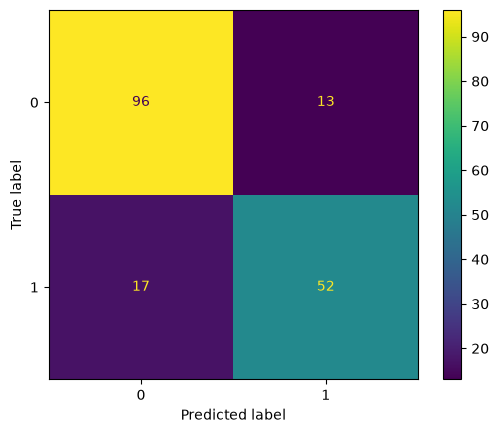

In [32]:
cm = confusion_matrix(y_test, y_test_pred, labels=model_KNN.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=model_KNN.classes_)
disp.plot()
plt.show()